# 02 — Weather features and first models

**Research question.** Can we predict overloads per route × weekday × period, and does **weather** improve the prediction beyond past ridership?

- Data: `data/processed/panel_weather.parquet` (panel 2022+ joined with Environment Canada weather; built by `src/weather.py`)
- Code: `src/train.py` (baselines, models, metrics); this notebook runs it and plots the results
- Split by time: **train 2022–2024 · validation 2025 · test 2026 (Jan–Oct)**. The test set is only used in section 6, after the models were chosen on validation.

**Weather source.** Halifax Stanfield Int'l A (Climate ID 8202251, Station ID 50620), Environment Canada bulk CSV.
- Hourly data gives temperature, wind, visibility and a "Weather" text field. It has **no precipitation amounts** (100% missing at this station).
- Precipitation, snowfall and snow on ground therefore come from the **daily** file and are the same for all four periods of a day.
- Hourly timestamps are Local *Standard* Time (UTC−4 all year) and were converted to Halifax clock time before assigning AM/MID/PM/EVE.

**Assumption.** Weather for the *same* day and period is used as a feature. In practice a forecast would be available in advance, so the weather results measure the value of a *perfect* forecast (an upper bound).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import precision_recall_curve, average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import train as T
from weather import WEATHER_COLS
warnings.simplefilter("ignore")
FIG = ROOT / "reports" / "figures"

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF, GRAY = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#a3a29b"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110, "font.size": 10,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); print("saved", FIG / f"{name}.png")

pd.set_option("display.width", 200)
df = T.load_data()
df.groupby("split").agg(rows=("y", "size"), positives=("y", "sum"), positive_rate=("y", "mean")).loc[["train", "val", "test"]].round(4)

,rows,positives,positive_rate
split,,,
train,29800,2123,0.0712
val,9960,953,0.0957
test,8320,656,0.0788


## 1. Weather features

In [2]:
wf = pd.read_parquet(T.PROCESSED / "weather_features.parquet")
print(f"weather features: {wf.shape[0]:,} date x period rows, {wf.date.min():%Y-%m-%d} -> {wf.date.max():%Y-%m-%d}")
miss = (100 * df[WEATHER_COLS].isna().mean()).round(2).rename("missing_% (panel 2022+)")
desc = df[WEATHER_COLS].describe().T[["mean", "min", "50%", "max"]].round(2)
pd.concat([miss, desc], axis=1)

weather features: 7,184 date x period rows, 2021-12-01 -> 2026-10-31


,missing_% (panel 2022+),mean,min,50%,max
temp_mean,0.00,8.61,-20.04,8.72,32.72
temp_min,0.00,7.38,-22.90,7.40,32.20
wind_mean,0.00,18.54,1.00,17.20,62.60
wind_max,0.00,22.82,4.00,21.00,69.00
vis_min,0.00,17.06,0.00,24.10,24.10
wx_snow,0.02,0.09,0.00,0.00,1.00
wx_rain,0.02,0.14,0.00,0.00,1.00
wx_freezing,0.02,0.01,0.00,0.00,1.00
precip_mm,0.42,3.74,0.00,0.00,72.60
rain_mm,0.50,3.22,0.00,0.00,72.60


| Feature | Definition |
|---|---|
| `temp_mean`, `temp_min` | hourly temperature in the period (°C) |
| `wind_mean`, `wind_max` | hourly wind speed in the period (km/h) |
| `vis_min` | minimum visibility in the period (km) |
| `wx_snow`, `wx_rain`, `wx_freezing` | share of hours *with a weather report* whose text mentions snow / rain or drizzle / freezing rain, freezing drizzle or ice pellets. Reports are always present at the 3-hourly synoptic hours, so every period has at least one. |
| `precip_mm`, `rain_mm`, `snow_cm` | daily totals |
| `snow_ground_cm` | daily snow on ground. Missing May–Oct (and in shoulder months with no snowfall in the past 7 days) is set to 0; short winter gaps are carried forward up to 3 days. |
| `gust_max_kmh` | daily max gust. Only reported above ~31 km/h, so missing = 0. |
| `snow_cm_prev1d` | yesterday's snowfall (clean-up days) |
| `bad_weather` | 1 if any of: daily snow ≥ 2 cm with snow reported in the period; daily precip ≥ 15 mm with rain in the period; any freezing precipitation in the period; period wind ≥ 50 km/h. Visibility is *not* used because the airport is ~30 km inland and often foggy when the city isn't. |

saved C:\Users\user\Desktop\ML project\reports\figures\09_overload_rate_vs_weather.png


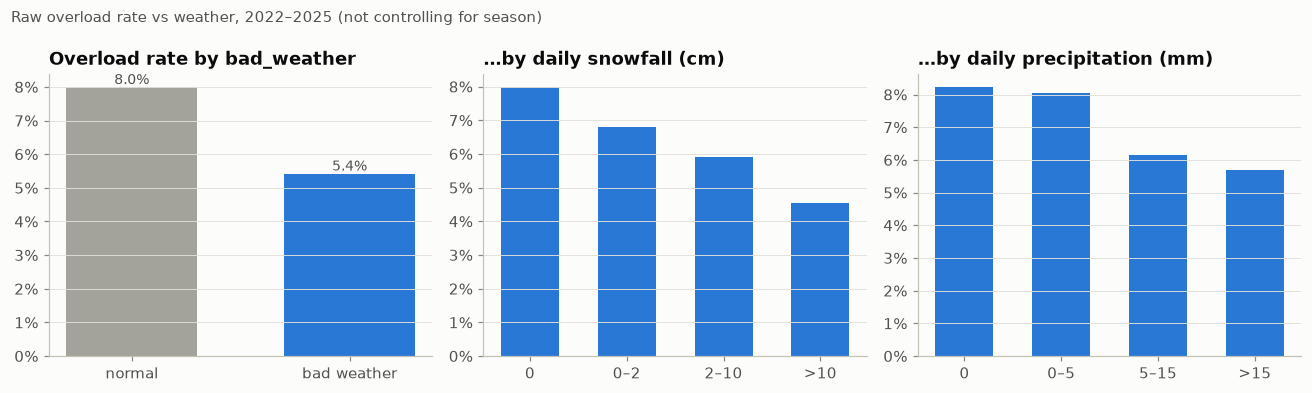

bad_weather share by month: {1: 0.19, 2: 0.2, 3: 0.17, 4: 0.08, 5: 0.04, 6: 0.04, 7: 0.03, 8: 0.05, 9: 0.06, 10: 0.09, 11: 0.05, 12: 0.18}


In [3]:
p = df[df.split != "test"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
r = p.groupby("bad_weather").y.mean()
axes[0].bar(["normal", "bad weather"], r.values, width=0.6, color=[GRAY, SERIES[0]])
axes[0].set_title("Overload rate by bad_weather")
for i, v in enumerate(r.values): axes[0].text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
bins = pd.cut(p.snow_cm, [-0.1, 0, 2, 10, 100], labels=["0", "0–2", "2–10", ">10"])
r = p.groupby(bins, observed=True).y.mean()
axes[1].bar(r.index.astype(str), r.values, width=0.6, color=SERIES[0]); axes[1].set_title("…by daily snowfall (cm)")
bins = pd.cut(p.precip_mm, [-0.1, 0, 5, 15, 200], labels=["0", "0–5", "5–15", ">15"])
r = p.groupby(bins, observed=True).y.mean()
axes[2].bar(r.index.astype(str), r.values, width=0.6, color=SERIES[0]); axes[2].set_title("…by daily precipitation (mm)")
for a in axes: a.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
fig.suptitle("Raw overload rate vs weather, 2022–2025 (not controlling for season)", x=0.01, ha="left", fontsize=10, color=INK2)
fig.tight_layout(); save(fig, "09_overload_rate_vs_weather"); plt.show()
print("bad_weather share by month:", p.groupby("month").bad_weather.mean().round(2).to_dict())

Raw rates are **lower** in bad weather. But bad weather is concentrated in winter, when overloads are rarer than in September–October, so this mixes weather with season. The models below compare like with like (route, period, month held fixed).

## 2. Validation: baselines, tuning and models

Baselines the ML models must beat:
1. **hist rate**: training-set overload rate for that route × period × month
2. **last week**: `y` from the previous non-holiday same weekday

Models: logistic regression (one-hot route/period/day/month, optional route×period interaction, log-scaled lags, scaled weather; `class_weight="balanced"`) and LightGBM (`scale_pos_weight` = negatives/positives, early stopping on validation PR-AUC). The tuning grids are small on purpose.

In [4]:
val_res, val_scores, selection = T.run_validation(df, verbose=False)
va = df[df.split == "val"]
cols = ["model", "pr_auc", "roc_auc", "brier", "recall_top5", "recall_top10", "recall_day5", "recall_day10", "params"]
print("prevalence (random-classifier PR-AUC):", round(va.y.mean(), 4))
val_res[cols].round(4)

prevalence (random-classifier PR-AUC): 0.0957


,model,pr_auc,roc_auc,brier,recall_top5,recall_top10,recall_day5,recall_day10,params
0,Baseline: hist rate,0.3207,0.8225,0.0746,0.2088,0.3882,0.2004,0.3589,NaN
1,Baseline: last week,0.1647,0.6215,0.1314,0.1605,0.3179,0.1490,0.2602,NaN
2,LogReg A_time,0.3703,0.8413,0.1542,0.2434,0.4250,0.2120,0.3998,"{""C"": 0.01, ""interact"": true}"
3,LightGBM A_time,0.3721,0.8481,0.1460,0.2340,0.4155,0.2141,0.3893,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
4,LogReg B_lags,0.3639,0.8391,0.1813,0.2361,0.4008,0.1952,0.3505,"{""C"": 0.01, ""interact"": true}"
5,LightGBM B_lags,0.3701,0.8443,0.1650,0.2361,0.4155,0.2046,0.3704,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
6,LogReg C_weather,0.3679,0.8395,0.1798,0.2434,0.4218,0.1952,0.3515,"{""C"": 0.01, ""interact"": true}"
7,LightGBM C_weather,0.3745,0.8443,0.1661,0.2319,0.4208,0.1952,0.3631,"{""num_leaves"": 7, ""min_child_samples"": 100, ""n..."


### Precision–recall curves (validation 2025)

saved C:\Users\user\Desktop\ML project\reports\figures\10_pr_curves_val.png


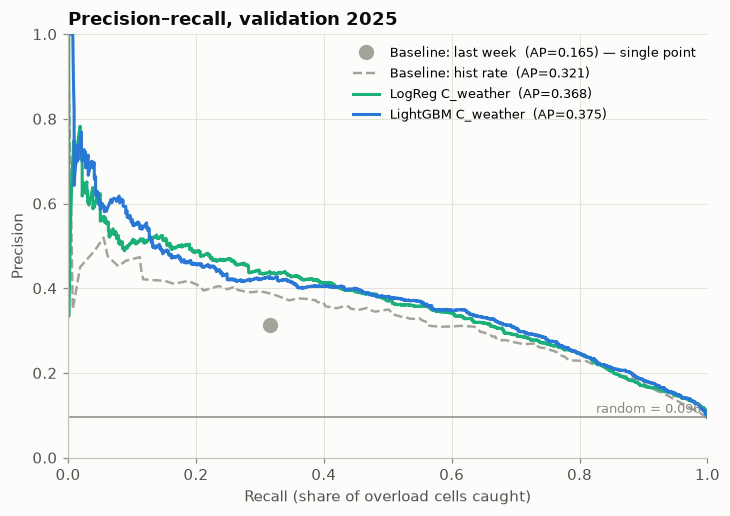

In [5]:
def pr_plot(d, scores, names, title, fname):
    styles = {"Baseline: hist rate": dict(color=GRAY, ls="--", lw=1.6),
              "Baseline: last week": dict(color=GRAY, ls=":", lw=1.6),
              "LogReg C_weather": dict(color=SERIES[2]), "LightGBM C_weather": dict(color=SERIES[0]),
              "LightGBM A_time": dict(color=SERIES[1], lw=1.6), "LightGBM B_lags": dict(color=SERIES[6], lw=1.6)}
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for n in names:
        sc = np.asarray(scores[n]); lab = f"{n}  (AP={average_precision_score(d.y, sc):.3f})"
        if set(np.unique(sc)) <= {0.0, 1.0}:          # binary score -> one operating point, not a curve
            yy = d.y.to_numpy(); flag = sc == 1
            ax.plot(yy[flag].sum() / yy.sum(), yy[flag].mean(), "o", ms=9, color=GRAY, label=lab + " — single point")
            continue
        pr, rc, _ = precision_recall_curve(d.y, sc)
        ax.plot(rc, pr, label=lab, **styles.get(n, {}))
    ax.axhline(d.y.mean(), color=MUTED, lw=1, ls="-")
    ax.text(0.99, d.y.mean() + 0.01, f"random = {d.y.mean():.3f}", ha="right", fontsize=8.5, color=MUTED)
    ax.set_xlabel("Recall (share of overload cells caught)"); ax.set_ylabel("Precision")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, axis="both"); ax.set_title(title)
    ax.legend(fontsize=8.5, loc="upper right")
    save(fig, fname); plt.show()

names = ["Baseline: last week", "Baseline: hist rate", "LogReg C_weather", "LightGBM C_weather"]
pr_plot(va, val_scores, names, "Precision–recall, validation 2025", "10_pr_curves_val")

## 3. Ablation on validation — is the difference real?

PR-AUC changes between feature sets are small, so we check (a) variation across 5 LightGBM random seeds and
(b) a **paired bootstrap over days** (resample whole dates, 1,000×) of the PR-AUC difference.

In [6]:
tr = df[df.split == "train"]
seed_scores, rows = {}, []
for fs in T.FEATURE_SETS:
    prm = selection[f"LightGBM {fs}"]; ps = []
    for seed in range(5):
        m = T.fit_lgbm(tr, T.FEATURE_SETS[fs], prm["num_leaves"], prm["min_child_samples"],
                       n_estimators=prm["n_estimators"], seed=seed)
        ps.append(m.predict_proba(va[T.FEATURE_SETS[fs]])[:, 1])
    aps = [average_precision_score(va.y, p) for p in ps]
    seed_scores[fs] = np.mean(ps, axis=0)
    rows.append({"feature_set": fs, "PR-AUC mean (5 seeds)": np.mean(aps), "sd": np.std(aps)})
display(pd.DataFrame(rows).round(4))
boot_val = pd.DataFrame([{"comparison": f"{a} -> {b}", **T.bootstrap_diff(va, seed_scores[a], seed_scores[b])}
                         for a, b in [("A_time", "B_lags"), ("B_lags", "C_weather"), ("A_time", "C_weather")]])
boot_val.round(4)

,feature_set,PR-AUC mean (5 seeds),sd
0,A_time,0.3710,0.0009
1,B_lags,0.3667,0.0024
2,C_weather,0.3731,0.0012


,comparison,diff,ci_low,ci_high,p_le_0
0,A_time -> B_lags,-0.0038,-0.0176,0.0116,0.680
1,B_lags -> C_weather,0.0057,0.0005,0.0109,0.012
2,A_time -> C_weather,0.0019,-0.0132,0.0175,0.404


In [7]:
v = va.copy(); v["rel"] = v.boardings_lag1w / v.boardings_mean4w
c = v.groupby(["route", "period", "month"], observed=True)[["rel", "y"]].apply(lambda g: g.rel.corr(g.y)).mean()
print(f"Why don't lags help? Within route x period x month, corr(last week / 4-week mean, y) = {c:.3f}")

Why don't lags help? Within route x period x month, corr(last week / 4-week mean, y) = 0.027


**Model choice (made on validation, before looking at test).** LightGBM with weather (C) has the best validation PR-AUC.
Logistic regression is close behind (0.37), so both go to the test stage, each with all three feature sets for the ablation.
Hyperparameters are fixed at their validation optimum (LightGBM: tree count from early stopping).

## 4. Test 2026 (Jan–Oct) — final evaluation

**Main result:** models trained on **2022–2024** with the hyperparameters chosen on validation.
**Sensitivity:** the same configurations refit on **2022–2025** (closer to 2026, i.e. what you would deploy).

In [8]:
te = df[df.split == "test"]
test_res, test_scores, test_models = T.run_test(df, selection, train_splits=("train",))
test_res_refit, test_scores_refit, _ = T.run_test(df, selection, train_splits=("train", "val"))
cols = ["model", "pr_auc", "roc_auc", "brier", "recall_top5", "incidents_top5", "recall_top10", "recall_day5", "recall_day10"]
print("Test prevalence:", round(te.y.mean(), 4), "| main: trained on 2022-2024")
display(test_res[cols].round(4))
print("Sensitivity: refit on 2022-2025")
test_res_refit[cols].round(4)

Test prevalence: 0.0788 | main: trained on 2022-2024


,model,pr_auc,roc_auc,brier,recall_top5,incidents_top5,recall_top10,recall_day5,recall_day10
0,Baseline: hist rate,0.2487,0.8035,0.0659,0.2058,0.2369,0.3826,0.2027,0.3399
1,Baseline: last week,0.1415,0.6148,0.1101,0.1966,0.2114,0.3064,0.1448,0.2470
2,LogReg A_time,0.2828,0.8236,0.1603,0.2530,0.3013,0.3796,0.1936,0.4207
3,LightGBM A_time,0.2919,0.8323,0.1507,0.2424,0.2868,0.3933,0.2088,0.3780
4,LogReg B_lags,0.2774,0.8236,0.1777,0.2409,0.2880,0.3933,0.1951,0.3171
5,LightGBM B_lags,0.2869,0.8235,0.1599,0.2317,0.2746,0.3811,0.2180,0.3476
6,LogReg C_weather,0.2764,0.8237,0.1773,0.2195,0.2576,0.3994,0.1966,0.3216
7,LightGBM C_weather,0.2886,0.8255,0.1611,0.2348,0.2783,0.3857,0.2104,0.3354


Sensitivity: refit on 2022-2025


,model,pr_auc,roc_auc,brier,recall_top5,incidents_top5,recall_top10,recall_day5,recall_day10
0,Baseline: hist rate,0.2649,0.8115,0.0646,0.2165,0.2588,0.3750,0.2088,0.3460
1,Baseline: last week,0.1415,0.6148,0.1101,0.1966,0.2114,0.3064,0.1448,0.2470
2,LogReg A_time,0.2887,0.8264,0.1634,0.2607,0.3111,0.3918,0.1936,0.4207
3,LightGBM A_time,0.2950,0.8345,0.1555,0.2668,0.3159,0.3979,0.1966,0.3872
4,LogReg B_lags,0.2890,0.8276,0.1717,0.2393,0.2855,0.4055,0.2165,0.3460
5,LightGBM B_lags,0.2909,0.8265,0.1578,0.2287,0.2673,0.3918,0.2241,0.3399
6,LogReg C_weather,0.2886,0.8283,0.1714,0.2332,0.2734,0.4024,0.2165,0.3491
7,LightGBM C_weather,0.2955,0.8298,0.1591,0.2363,0.2770,0.4024,0.2180,0.3476


saved C:\Users\user\Desktop\ML project\reports\figures\11_pr_curves_test.png


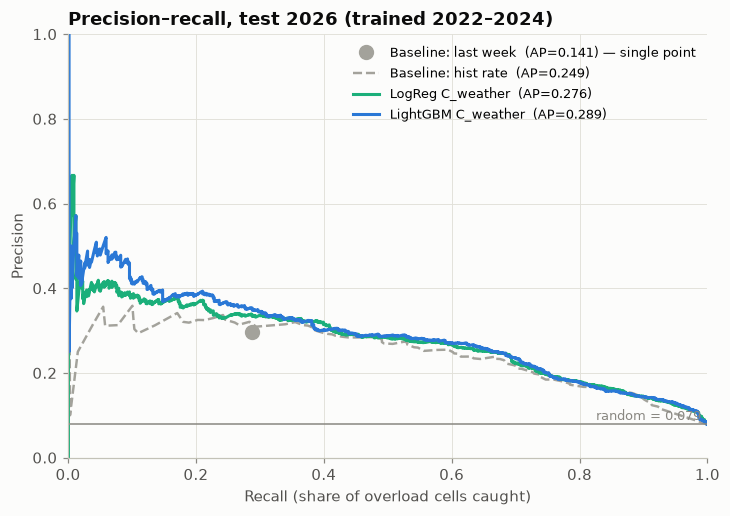

In [9]:
pr_plot(te, test_scores, names, "Precision–recall, test 2026 (trained 2022–2024)", "11_pr_curves_test")

### Ablation (research question): validation vs test

saved C:\Users\user\Desktop\ML project\reports\figures\12_ablation_pr_auc.png


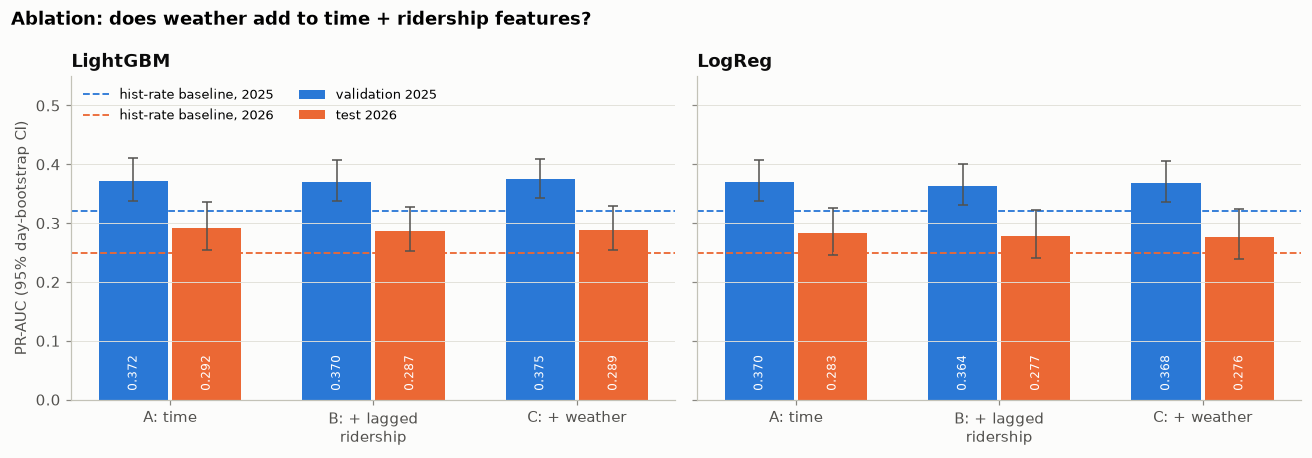

,model,comparison,diff,ci_low,ci_high,p_le_0
0,LightGBM,A_time -> B_lags,-0.0050,-0.0211,0.0127,0.683
1,LightGBM,B_lags -> C_weather,0.0017,-0.0050,0.0079,0.311
2,LightGBM,A_time -> C_weather,-0.0033,-0.0196,0.0138,0.618
3,LogReg,A_time -> B_lags,-0.0054,-0.0185,0.0081,0.754
4,LogReg,B_lags -> C_weather,-0.0011,-0.0088,0.0072,0.577
5,LogReg,A_time -> C_weather,-0.0064,-0.0214,0.0101,0.752


In [10]:
def boot_ap(d, s, n=1000, seed=0):
    rng = np.random.default_rng(seed); dates = d.date.to_numpy(); u, inv = np.unique(dates, return_inverse=True)
    by = [np.flatnonzero(inv == i) for i in range(len(u))]; y = d.y.to_numpy(); s = np.asarray(s); out = []
    for _ in range(n):
        k = np.concatenate([by[i] for i in rng.integers(0, len(u), len(u))]); out.append(average_precision_score(y[k], s[k]))
    return np.percentile(out, [2.5, 97.5])

abl = []
for fam in ["LightGBM", "LogReg"]:
    for fs in T.FEATURE_SETS:
        n = f"{fam} {fs}"
        for split, d, sc in [("validation 2025", va, val_scores), ("test 2026", te, test_scores)]:
            lo, hi = boot_ap(d, sc[n])
            abl.append({"model": fam, "feature_set": fs, "split": split,
                        "pr_auc": average_precision_score(d.y, sc[n]), "lo": lo, "hi": hi})
abl = pd.DataFrame(abl)
base = {s: average_precision_score(d.y, sc["Baseline: hist rate"]) for s, d, sc in
        [("validation 2025", va, val_scores), ("test 2026", te, test_scores)]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
labels = {"A_time": "A: time", "B_lags": "B: + lagged\nridership", "C_weather": "C: + weather"}
for ax, fam in zip(axes, ["LightGBM", "LogReg"]):
    for j, (split, col) in enumerate([("validation 2025", SERIES[0]), ("test 2026", SERIES[1])]):
        s = abl[(abl.model == fam) & (abl.split == split)]
        x = np.arange(3) + (j - 0.5) * 0.36
        ax.bar(x, s.pr_auc, width=0.34, color=col, label=split)
        ax.errorbar(x, s.pr_auc, yerr=[s.pr_auc - s.lo, s.hi - s.pr_auc], fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
        for xi, v in zip(x, s.pr_auc): ax.text(xi, 0.02, f"{v:.3f}", ha="center", fontsize=8, color="#ffffff", rotation=90)
        ax.axhline(base[split], color=col, ls="--", lw=1.2, label=f"hist-rate baseline, {split[-4:]}")
    ax.set_xticks(range(3), [labels[k] for k in T.FEATURE_SETS]); ax.set_title(fam)
    ax.set_ylim(0, 0.5)
axes[0].set_ylabel("PR-AUC (95% day-bootstrap CI)")
axes[0].legend(loc="upper left", ncol=2, fontsize=8.5)
axes[0].set_ylim(0, 0.55); axes[1].set_ylim(0, 0.55)
fig.suptitle("Ablation: does weather add to time + ridership features?", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "12_ablation_pr_auc"); plt.show()

boot_test = pd.DataFrame([{"model": fam, "comparison": f"{a} -> {b}",
                           **T.bootstrap_diff(te, test_scores[f"{fam} {a}"], test_scores[f"{fam} {b}"])}
                          for fam in ["LightGBM", "LogReg"]
                          for a, b in [("A_time", "B_lags"), ("B_lags", "C_weather"), ("A_time", "C_weather")]])
boot_test.round(4)

### What would a top-5% flag have caught in 2026?

In [11]:
best = "LightGBM C_weather"
rows = []
for n in ["Baseline: hist rate", "LogReg C_weather", "LightGBM A_time", "LightGBM B_lags", best]:
    s = np.asarray(test_scores[n]); rng = np.random.default_rng(0)
    order = np.lexsort((rng.random(len(s)), -s)); k = int(np.ceil(0.05 * len(s))); top = order[:k]
    tmp = te.assign(s=s + 1e-12 * rng.random(len(s)))
    day = (tmp.groupby("date").s.rank(ascending=False, method="first") <= 2).to_numpy()
    rows.append({"model": n, "cells flagged (top 5%)": k,
                 "overload cells caught": int(te.y.to_numpy()[top].sum()), "of": int(te.y.sum()),
                 "incidents caught": int(te.n_overloads.to_numpy()[top].sum()), "of incidents": int(te.n_overloads.sum()),
                 "precision of flags": te.y.to_numpy()[top].mean(),
                 "daily budget 2/40: cells caught": int(te.y.to_numpy()[day].sum())})
pd.DataFrame(rows).round(3)

,model,cells flagged (top 5%),overload cells caught,of,incidents caught,of incidents,precision of flags,daily budget 2/40: cells caught
0,Baseline: hist rate,416,135,656,195,823,0.325,133
1,LogReg C_weather,416,144,656,212,823,0.346,129
2,LightGBM A_time,416,159,656,236,823,0.382,137
3,LightGBM B_lags,416,152,656,226,823,0.365,143
4,LightGBM C_weather,416,154,656,229,823,0.370,138


## 5. What drives the predictions?

saved C:\Users\user\Desktop\ML project\reports\figures\13_shap_importance.png


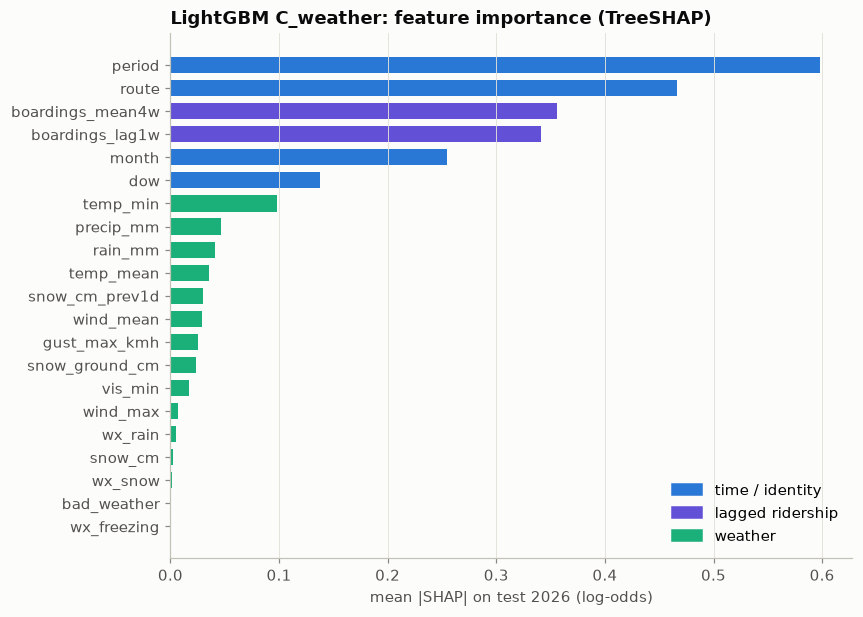

share of total |SHAP| by group: {'lagged ridership': 0.277, 'time / identity': 0.579, 'weather': 0.144}



weather: corr(feature value, SHAP) (>0 = higher value -> higher overload risk):
wx_rain          -0.83
gust_max_kmh     -0.83
rain_mm          -0.71
precip_mm        -0.65
snow_cm          -0.63
wx_snow          -0.45
wind_mean        -0.42
wind_max          0.06
temp_mean         0.57
snow_cm_prev1d    0.78
temp_min          0.81
vis_min           0.91
snow_ground_cm    0.94
wx_freezing        NaN
bad_weather        NaN


In [12]:
m, feats = test_models[best]           # LightGBM C_weather trained on 2022-2024
contrib = m.booster_.predict(te[feats], pred_contrib=True)[:, :-1]     # exact TreeSHAP (log-odds)
shap_imp = pd.Series(np.abs(contrib).mean(axis=0), index=feats).sort_values()
group = {f: ("time / identity" if f in T.TIME else "lagged ridership" if f in T.LAGS else "weather") for f in feats}
gcol = {"time / identity": SERIES[0], "lagged ridership": SERIES[6], "weather": SERIES[2]}
fig, ax = plt.subplots(figsize=(8, 6.2))
ax.barh(shap_imp.index, shap_imp.values, height=0.7, color=[gcol[group[f]] for f in shap_imp.index])
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in gcol.items()], loc="lower right"); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean |SHAP| on test 2026 (log-odds)"); ax.set_title(f"{best}: feature importance (TreeSHAP)")
save(fig, "13_shap_importance"); plt.show()
print("share of total |SHAP| by group:",
      (pd.Series(np.abs(contrib).mean(axis=0), index=feats).groupby(group).sum() / np.abs(contrib).mean(axis=0).sum()).round(3).to_dict())

# direction of the weather effects: correlation between feature value and its SHAP value
wx_dir = pd.Series({f: np.corrcoef(te[f].fillna(te[f].median()), contrib[:, feats.index(f)])[0, 1]
                    for f in T.WEATHER}).round(2)
print("\nweather: corr(feature value, SHAP) (>0 = higher value -> higher overload risk):")
print(wx_dir.sort_values().to_string())

saved

 C:\Users\user\Desktop\ML project\reports\figures\14_logreg_coefficients.png


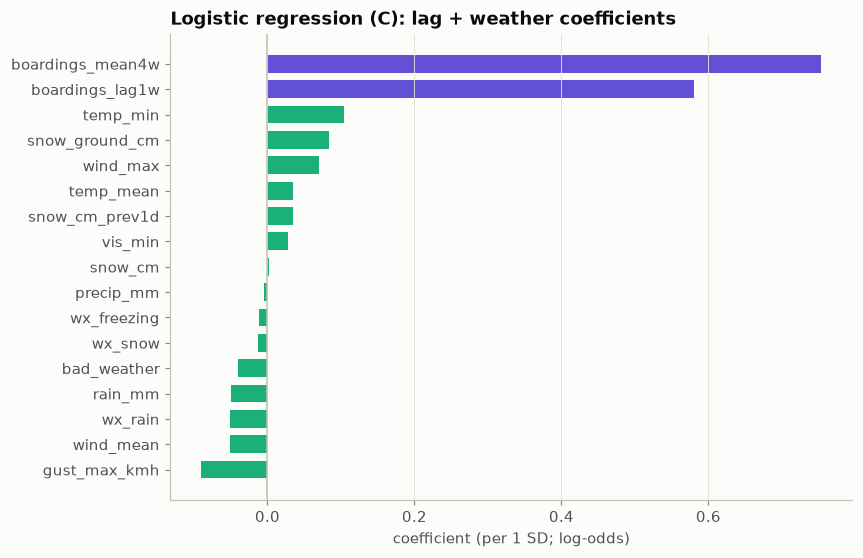

largest one-hot effects:
 cat__route_1              -1.00
cat__route_90              0.89
cat__route_9B              0.84
cat__month_9               0.81
cat__period_PM             0.68
cat__route_period_9B_PM    0.61
cat__period_EVE           -0.60
cat__route_period_3_AM     0.59
cat__route_period_8_PM     0.56
cat__route_period_90_AM    0.55
cat__route_2              -0.53
cat__month_6              -0.52


In [13]:
lr, cols_lr = test_models["LogReg C_weather"]
names_lr = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names_lr)
cont = coef[[n.startswith(("lag__", "wx__")) for n in names_lr]].sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([n.split("__", 1)[1] for n in cont.index], cont.values, height=0.7,
        color=[SERIES[6] if n.startswith("lag__") else SERIES[2] for n in cont.index])
ax.axvline(0, color=AXIS, lw=1); ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.set_xlabel("coefficient (per 1 SD; log-odds)"); ax.set_title("Logistic regression (C): lag + weather coefficients")
save(fig, "14_logreg_coefficients"); plt.show()
top_cat = coef[[n.startswith("cat__") for n in names_lr]]
print("largest one-hot effects:\n", top_cat.reindex(top_cat.abs().sort_values(ascending=False).index).head(12).round(2).to_string())

## 6. Drift check: does the training-period rate carry over to 2026?

In [14]:
s = np.asarray(test_scores[best]); v_s = np.asarray(val_scores[best])
hist = df.groupby("year").y.mean()
mon = te.assign(pred=s).groupby("month").agg(actual=("y", "mean"), mean_score=("pred", "mean"))
print("positive rate by year:", hist.round(4).to_dict())
print("mean LightGBM score (class-weighted, so not a calibrated probability): val", round(v_s.mean(), 3), "test", round(s.mean(), 3))
pr_month = te.assign(pred=s).groupby("month").apply(lambda g: average_precision_score(g.y, g.pred) if g.y.sum() else np.nan)
mon["pr_auc"] = pr_month
mon.round(3).T

positive rate by year: {2022: 0.0299, 2023: 0.0882, 2024: 0.0953, 2025: 0.0957, 2026: 0.0788}
mean LightGBM score (class-weighted, so not a calibrated probability): val 0.353 test 0.335


month,1,2,3,4,5,6,7,8,9,10
actual,0.090,0.076,0.070,0.071,0.061,0.059,0.051,0.072,0.115,0.124
mean_score,0.308,0.330,0.285,0.295,0.278,0.303,0.326,0.332,0.449,0.446
pr_auc,0.277,0.230,0.189,0.242,0.366,0.303,0.445,0.291,0.364,0.337


## 7. Summary (round 2, 2026-11-08)

**Which model works best?** Gradient boosting (LightGBM) is the best model, but only narrowly.

| PR-AUC | random | last week | hist rate | LogReg (A/B/C) | LightGBM (A/B/C) |
|---|---|---|---|---|---|
| validation 2025 | 0.096 | 0.165 | 0.321 | 0.364–0.370 | **0.370–0.375** |
| test 2026 | 0.079 | 0.141 | 0.249 | 0.276–0.283 | **0.287–0.292** |

- Both ML models beat both baselines on the untouched 2026 test set: about +0.04 PR-AUC over the historical route × period × month rate. ROC-AUC is about 0.83.
- Logistic regression is only about 0.01 behind LightGBM.
- Most of the predictive power comes from **period, route, month and day of week**; the models mainly learn *where and when* overloads happen.

**Does weather help beyond ridership?** **No, not reliably**, even under the generous perfect-forecast assumption.
- Validation: + weather (B → C) gave a small gain of +0.006 PR-AUC (95% day-bootstrap CI [+0.0005, +0.011]).
- Test: that gain **did not replicate**: +0.002 (CI [−0.005, +0.008]). For logistic regression it was −0.001.
- Test, time-only (A) vs. with weather (C): −0.003 for LightGBM.
- Weather gets 14% of the model's SHAP importance. The largest weather feature is `temp_min`, which mostly acts as a season proxy.
- Weather effects point the same way in both models. Rain, gusts and heavy snowfall → *lower* overload risk (fewer riders, consistent with the EDA). Snow on the ground and yesterday's snowfall → slightly *higher* risk (a hypothesis: slower buses and bunching, or fewer people walking or cycling). These effects are too small to change the ranking.
- Lagged ridership doesn't add predictive value either (A → B: −0.005 on test). It gets 28% of SHAP importance, but it mostly duplicates the route × period identity. Within a route × period × month, last week's relative ridership barely relates to overloads (correlation 0.03).

**How much would a top-5% flag have caught in 2026?** Ranking the 8,320 test route-periods (Jan–Oct 2026) by the final model (LightGBM C, trained 2022–2024) and flagging the top 5% (416 cells):
- catches **154 of 656 overload cells (23%)**, covering **229 of 823 reported incidents (28%)**, at 37% precision;
- vs. the historical-rate baseline: 135 cells and 195 incidents;
- with a fixed daily budget of 2 of each day's 40 route-periods: 138 cells (21%);
- refitting on 2022–2025 changes little (PR-AUC 0.296, similar recall).

**Problems and caveats.**
- **Drift in the overload rate:** 3.0% in 2022, about 9% in 2023–2025, 7.9% in 2026. The training data mixes a low-overload 2022 with later years. PR-AUC depends on the base rate, so much of the drop from validation (0.37) to test (0.29) reflects 2026's lower prevalence; ROC-AUC barely changes (0.84 → 0.83).
- **Probabilities aren't calibrated:** class weighting makes LightGBM's mean score about 0.33 while the true rate is 0.079, so its Brier score (0.16) is worse than the baseline's (0.066). The ranking metrics are unaffected. If calibrated risks are needed, recalibrate on validation (Platt/isotonic) or train without class weights.
- **Weather data limits:** Stanfield is an inland airport about 30 km from downtown with no hourly precipitation amounts, so precipitation and snow are daily values shared by all four periods. A downtown station, or radar-based precipitation, might show more.
- **Optimistic validation numbers:** validation scores are slightly optimistic because early stopping used the validation set. The test numbers are clean: the test set was used once, after model choice.
- **Not tried yet:** the university academic calendar, overload-history features (e.g. overloads in the previous 4 weeks), and recalibration. Overload history is the most promising lead given the drift.
- **Environment:** LightGBM 4.7 crashed intermittently (native access violation) on this machine, so LightGBM 4.5.0 and numpy 2.1.3 are pinned. Results were identical under both versions.